# Function 5 - Week 5: Model Predictions

#### Model Predictions using Official Observations up to and including Week 4 return, received on **23 October 2026**.

Read [the Week 5 report](report.md) for model interpretation, query selection and limitations.

In [1]:
%matplotlib inline

# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "model_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review
from model_review_helpers import (
    make_regression_models, fit_model_review, review_latest_predictions,
    build_review_candidates, score_review_candidates,
    query_prediction, weight_sensitivity, noise_sensitivity,
)
from model_review_plots import plot_held_out_comparison, plot_latest_predictions
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries
from plot_helpers import PLOT_CONFIG
from model_review_plots import plot_coordinate_model_review
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor

from scipy.spatial.distance import cdist

# Require the shared Capstone environment, even if another kernel was selected.
repository_dir = next(folder for folder in Path.cwd().parents if (folder / "run-python.ps1").is_file())
expected_interpreter = repository_dir / ".venv" / "Scripts" / "python.exe"
if Path(sys.executable).resolve() != expected_interpreter.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {expected_interpreter}")
print(f"Python interpreter: {sys.executable}")


Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Settings for this run. Keep model assumptions and search settings here.
FUNCTION_NUMBER = 5
CURRENT_WEEK = 5
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4']
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 20, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
PORTAL_DECIMALS = 6
MODEL_NAMES = ["Mean baseline", "Linear regression", "Ridge", "Kernel ridge", "Gaussian process"]
GP_NAMES = ["Gaussian process"]
# Retain the existing GP diagonal regularisation; it is not a measured noise level.
MODEL_SETTINGS = dict(
    noise_fraction=0.10, ridge_alpha=1.0,
    kernel_ridge_alpha=0.1, kernel_ridge_gamma=1.0,
    length_scale=0.3, length_scale_bounds=(0.03, 2.0),
    amplitude=1.0, amplitude_bounds=(0.01, 100.0), optimiser_restarts=3, seed=42,
)
EXPLORATION_WEIGHT = 1.96
SEARCH_SETTINGS = dict(
    broad_power=14, broad_seed=42, local_power=12, local_seed=43,
    local_radius=0.15, precision=PORTAL_DECIMALS, include_corners=True,
)
COVERAGE_SETTINGS = dict(
    max_queries=1, optimization_power=12, evaluation_power=15,
    optimization_seed=42, evaluation_seed=43, comparison_seed=42, verbose=False,
)
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)
VALIDATION_MODELS = ["Ridge", "Kernel ridge"]
COORDINATE_VIEW_SETTINGS = dict(side=250, padding_fraction=0.05, figsize=(18.0, 5.3))
CANDIDATES_TO_SHOW = 5
VALIDATION_SIZE = (15, 5)
LATEST_RESULT_SIZE = (11, 5.5)
REGULARISATION_FRACTIONS = (0.03, 0.10, 0.30)

LOG_TARGET_MODEL = "GP with log target (median)"

# A budget safeguard after two non-improving near-corner returns, not a fitted optimum.
MIN_QUERY_DISTANCE = 0.02
DISTANCE_THRESHOLDS = (0.0, 0.01, 0.02, 0.05)


In [3]:
# Validate the same snapshot used by the exploration review.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
if not np.all(raw_y > 0):
    raise ValueError("The log-target comparison needs positive outputs.")


,observation_id,source_round,x1,x2,x3,x4,y,output_rank
23,round-04,4,0.999515,0.989282,0.999999,0.999999,8449.982375,3


In [4]:
# Fit each complete estimator within every held-out fold.
models = make_regression_models(len(INPUT_COLUMNS), **MODEL_SETTINGS)
models = {name: models[name] for name in MODEL_NAMES}
models[LOG_TARGET_MODEL] = TransformedTargetRegressor(
    regressor=clone(models["Gaussian process"]), func=np.log, inverse_func=np.exp,
)
# Compare back-transformed medians in original units; retain raw-output GP query selection.
model_run = fit_model_review(models, inputs, raw_y, gp_names=GP_NAMES)
selected_model = model_run["selected_model"]
modelled_axes = tuple(range(len(INPUT_COLUMNS)))
display(model_run["table"].round(6))
display(pd.Series({"Selected GP": model_run["selected_name"], "Fitted kernel": model_run["fitted_kernel"]}))

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,Gaussian process,91.363581,280.611217,334.683703,0.133688,88.659844
1,Kernel ridge,196.443472,339.969505,423.669511,0.161967,85.644719
2,GP with log target (median),15.971586,155.753967,440.384778,0.074204,85.078352
3,Linear regression,1115.671177,1420.533068,1655.140374,0.676767,43.918540
4,Ridge,1113.124282,1325.450254,1703.662708,0.631468,42.274448
5,Mean baseline,2011.541589,2098.999919,2951.314710,1.000000,0.000000


Selected GP                       Gaussian process
Fitted kernel    1.33**2 * RBF(length_scale=0.949)
dtype: str

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,GP with log target (median),8451.1619,1.1796,0.0140,0.0000,449.8564
1,Gaussian process,8484.7685,34.7861,0.4117,0.0450,341.8051
2,Kernel ridge,7960.7292,-489.2532,5.7900,5.5565,420.5861
3,Linear regression,6280.5247,-2169.4577,25.6741,7.1585,1629.0996
4,Ridge,4915.9391,-3534.0432,41.8231,17.9294,1576.5915
5,Mean baseline,1049.8583,-7400.1240,87.5756,26.1960,2589.9838


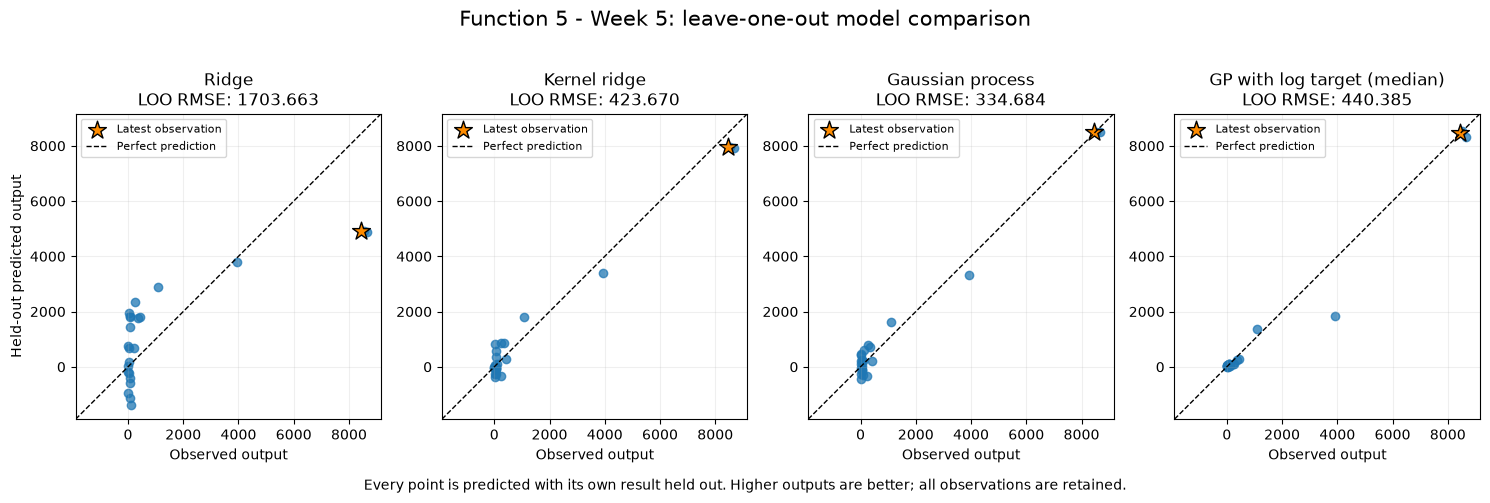

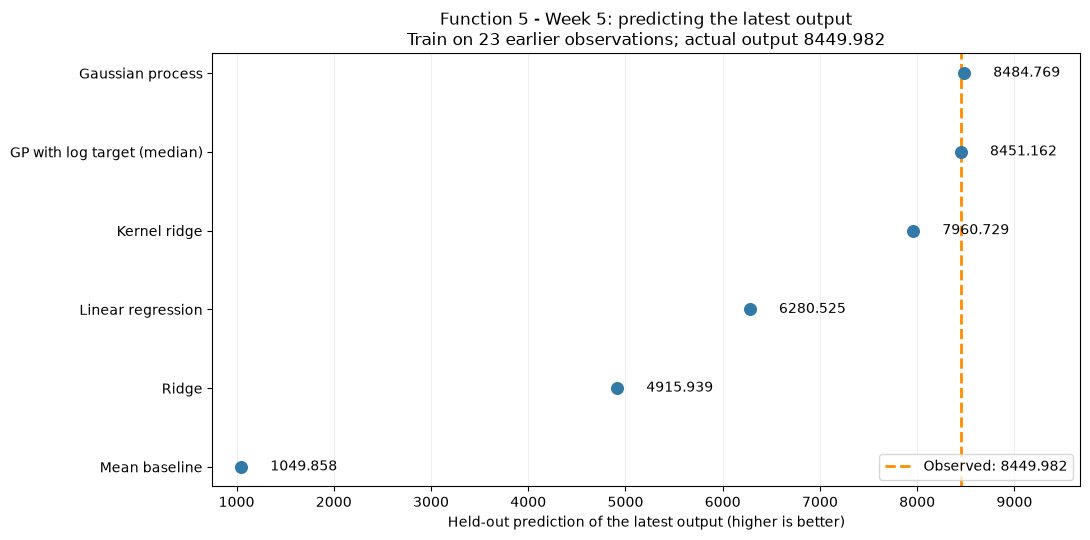

In [5]:
# This checks the latest held-out result retrospectively; it is not a saved forecast.
latest_review = review_latest_predictions(model_run["predictions"], raw_y, review["latest_mask"])
latest_output = float(raw_y[review["latest_mask"]][0])
display(latest_review.round(4))
display(plot_held_out_comparison(
    model_run["predictions"], raw_y,
    model_names=[*VALIDATION_MODELS, model_run["selected_name"], LOG_TARGET_MODEL], latest_mask=review["latest_mask"],
    title=f"{TITLE}: leave-one-out model comparison", figsize=VALIDATION_SIZE,
    save_to=FIGURES_DIR / "model-comparison-validation.png",
))
display(plot_latest_predictions(
    latest_review, latest_output, n_training_rows=int((~review["latest_mask"]).sum()),
    title=f"{TITLE}: predicting the latest output", figsize=LATEST_RESULT_SIZE,
    save_to=FIGURES_DIR / "latest-output-predictions.png",
))

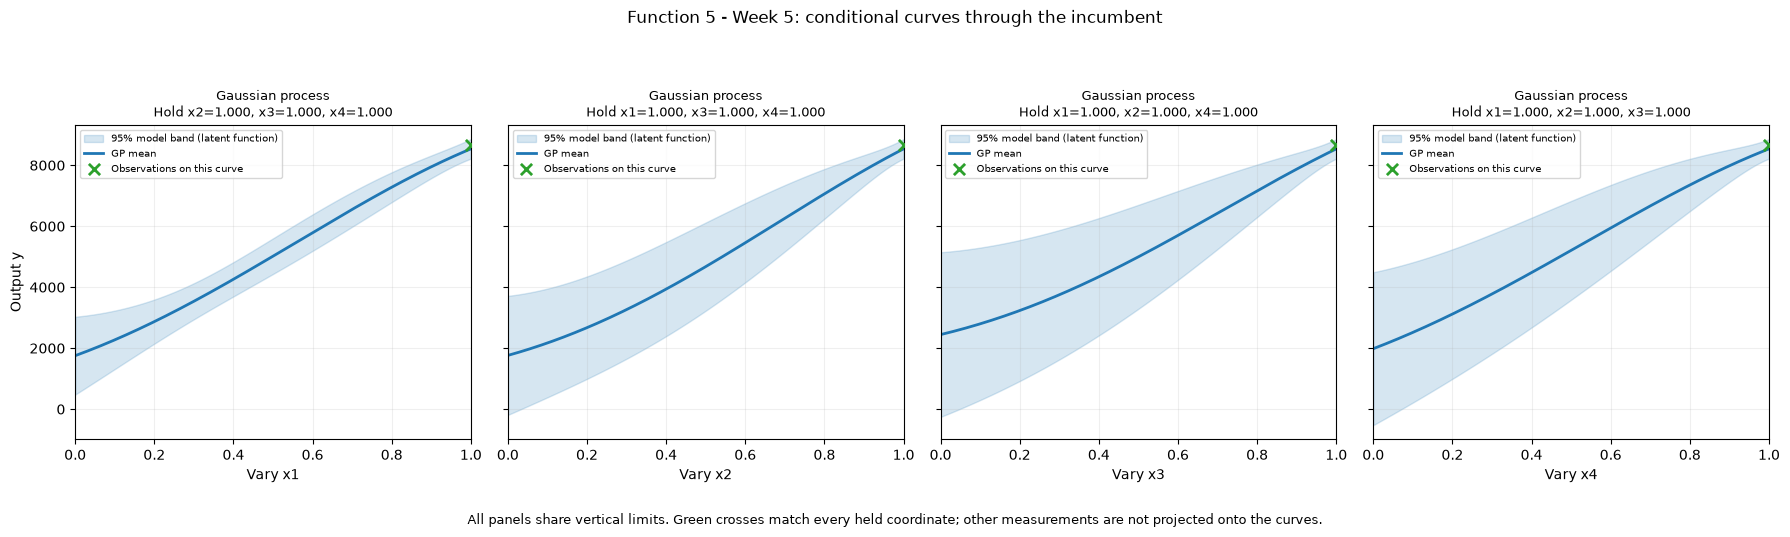

In [6]:
# Vary one coordinate at a time through the measured incumbent, holding all others fixed.
coordinate_figure = plot_coordinate_model_review(
    {name: model_run["fitted"][name] for name in GP_NAMES}, inputs, raw_y, anchor,
    input_columns=INPUT_COLUMNS, title=f"{TITLE}: conditional curves through the incumbent",
    **COORDINATE_VIEW_SETTINGS, save_to=None,
)
# Wrap the held-coordinate settings so the higher-dimensional panels remain readable.
from textwrap import fill
for coordinate_axis in coordinate_figure.axes:
    model_label, held_settings = coordinate_axis.get_title().split("\n", 1)
    coordinate_axis.set_title(model_label + "\n" + fill(held_settings, width=34), fontsize=9)
coordinate_figure.tight_layout(rect=(0, 0.06, 1, 0.92))
coordinate_figure.savefig(FIGURES_DIR / "gp-coordinate-slices.png", dpi=160, bbox_inches="tight")
display(coordinate_figure)


In [7]:
# Reuse the geometric coverage cache, then score the exact rounded candidate inputs.
coverage = compare_coverage_batches(
    existing=inputs, cache_dir=ANALYSIS_DIR / ".coverage-cache", **COVERAGE_SETTINGS,
)
candidates = build_review_candidates(
    inputs, anchor, coverage["proposed_batches"][1], input_columns=INPUT_COLUMNS, **SEARCH_SETTINGS,
)
candidates["nearest_observed_distance"] = cdist(candidates[INPUT_COLUMNS], inputs).min(axis=1)
all_scored = score_review_candidates(
    selected_model, candidates, input_columns=INPUT_COLUMNS,
    weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
# Keep the same GP and candidate scores; apply the declared geometric spacing safeguard.
spacing_rows = []
for threshold in DISTANCE_THRESHOLDS:
    eligible = all_scored.loc[all_scored.nearest_observed_distance >= threshold]
    if eligible.empty:
        raise ValueError("No candidate meets the declared distance threshold.")
    best = eligible.iloc[0]
    spacing_rows.append({"Minimum distance": threshold,
        "Portal input": "-".join(f"{best[col]:.6f}" for col in INPUT_COLUMNS),
        "Nearest measured input": best.nearest_observed_distance,
        "Predicted output": best.posterior_mean, "Posterior SD": best.posterior_sd,
        "UCB": best.ucb, "Eligible candidates": len(eligible)})
spacing_review = pd.DataFrame(spacing_rows)
scored = all_scored.loc[all_scored.nearest_observed_distance >= MIN_QUERY_DISTANCE].reset_index(drop=True)
display(spacing_review)
by_source = scored.loc[scored.groupby("candidate_source")["ucb"].idxmax()].sort_values("ucb", ascending=False)
display(by_source.round(6))
display(pd.DataFrame(coverage["results"]))

,Minimum distance,Portal input,Nearest measured input,Predicted output,Posterior SD,UCB,Eligible candidates
0,0.00,0.999999-0.999999-0.999942-0.999999,0.000057,8537.334050,163.425321,8857.647679,20255
1,0.01,0.999999-0.999999-0.999999-0.989835,0.010164,8485.293185,164.933254,8808.562362,20154
2,0.02,0.999999-0.999999-0.999999-0.979636,0.020363,8431.759823,169.622719,8764.220351,20059
3,0.05,0.999999-0.999999-0.999999-0.949598,0.050401,8268.721005,198.150541,8657.096067,19696


,x1,x2,x3,x4,posterior_mean,posterior_sd,ucb,candidate_source,nearest_observed_distance
0,0.999999,0.999999,0.999999,0.979636,8431.759823,169.622719,8764.220351,Near incumbent,0.020363
1080,0.986623,0.953357,0.992406,0.977525,7977.801840,176.292325,8323.334797,Full input space,0.044939
12905,0.124725,0.114841,0.611911,0.902685,-908.602373,954.462564,962.144253,Single coverage query,0.498587


,q,max_distance,p95_distance
0,0,0.731397,0.491065
1,1,0.684003,0.468796


In [8]:
# Every coordinate remains free in the rounded candidate comparison.
recommended = scored.iloc[0]
next_query = recommended[INPUT_COLUMNS].to_numpy(dtype=float)
proposal = query_prediction(
    selected_model, next_query, inputs, raw_y, weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
proposal_source = recommended.candidate_source
display(pd.Series(proposal))

point                         [0.999999, 0.999999, 0.999999, 0.979636]
predicted_output                                           8431.759823
posterior_std                                               169.622719
ucb                                                        8764.220351
predicted_mean_improvement                                 -230.645179
inside_sampled_hull                                              False
portal_input                       0.999999-0.999999-0.999999-0.979636
dtype: object

In [9]:
# Reuse the same candidate pool and predictions while changing the exploration weight.
exploration_sensitivity = weight_sensitivity(
    scored, inputs, input_columns=INPUT_COLUMNS, modelled_axes=modelled_axes,
    weights=EXPLORATION_WEIGHTS, precision=PORTAL_DECIMALS,
)
display(exploration_sensitivity.round(6))

,Weight,x1,x2,x3,x4,Predicted output,Posterior SD
0,0.00,0.999999,0.999999,0.999999,0.979636,8431.759823,169.622719
1,1.00,0.999999,0.999999,0.999999,0.979636,8431.759823,169.622719
2,1.96,0.999999,0.999999,0.999999,0.979636,8431.759823,169.622719
3,3.00,0.999999,0.999999,0.999999,0.979636,8431.759823,169.622719


In [10]:
# Retain every coordinate in the alternatives; these predictions are not measured outputs.
display(scored.head(CANDIDATES_TO_SHOW)[[
    *INPUT_COLUMNS, "posterior_mean", "posterior_sd", "ucb", "candidate_source",
]].round(PORTAL_DECIMALS))

,x1,x2,x3,x4,posterior_mean,posterior_sd,ucb,candidate_source
0,0.999999,0.999999,0.999999,0.979636,8431.759823,169.622719,8764.220351,Near incumbent
1,0.999999,0.999999,0.999999,0.979340,8430.192090,169.802978,8763.005928,Near incumbent
2,0.999999,0.999999,0.999999,0.978776,8427.202743,170.153004,8760.702630,Near incumbent
3,0.999999,0.999999,0.999999,0.977893,8422.516873,170.718127,8757.124401,Near incumbent
4,0.999999,0.999999,0.999999,0.977371,8419.743452,171.061940,8755.024854,Near incumbent


In [11]:
# Check the same input under alternative GP diagonal regularisation assumptions.
# These fractions do not estimate repeat-evaluation noise or reselect the query.
regularisation_sensitivity = noise_sensitivity(
    selected_model, inputs, raw_y, next_query, fractions=REGULARISATION_FRACTIONS,
    fitted_noise_fraction=MODEL_SETTINGS["noise_fraction"],
)
display(regularisation_sensitivity.round(6))


,Assumed noise fraction,Predicted output,Posterior SD
0,0.03,8476.985807,73.171169
1,0.10,8431.759823,169.622719
2,0.30,8147.800644,476.979352


In [12]:
# Save the Week 5 proposal and its review evidence; no portal request is made.
analysis_summary = {
    "minimum_query_distance": MIN_QUERY_DISTANCE,
    "nearest_observed_distance": float(recommended.nearest_observed_distance),
    "candidate_count_before_spacing": len(all_scored),
    "spacing_sensitivity": spacing_review.to_dict(orient="records"),
    "python_executable": sys.executable,
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(raw_y),
    "query_model": model_run["selected_name"], "proposal_status": "proposed_not_submitted",
    "portal_input": proposal["portal_input"], "point": proposal["point"],
    "predicted_output": proposal["predicted_output"], "posterior_std": proposal["posterior_std"],
    "ucb_weight": EXPLORATION_WEIGHT, "candidate_source": proposal_source,
    "candidate_count": len(scored),
    "inside_sampled_hull": proposal["inside_sampled_hull"], "best_observed_output": float(raw_y.max()),
    "gp_rmse": model_run["selected_rmse"], "baseline_rmse": model_run["baseline_rmse"],
    "gp_baseline_rmse_ratio": model_run["selected_rmse"] / model_run["baseline_rmse"],
    "lowest_rmse_model": model_run["table"].iloc[0]["Model"],
    "distinct_weight_choices": len(exploration_sensitivity[INPUT_COLUMNS].drop_duplicates()),
    "remaining_queries": remaining_queries(WEEK_DIR),
    "model_comparison": model_run["table"].to_dict(orient="records"),
    "fitted_kernel": model_run["fitted_kernel"],
    "length_scales": np.atleast_1d(selected_model.kernel_.k2.length_scale).tolist(),
    "weight_sensitivity": exploration_sensitivity.to_dict(orient="records"),
    "regularisation_sensitivity": regularisation_sensitivity.to_dict(orient="records"),
    "proposal": proposal,
    "latest_prediction_review": latest_review.to_dict(orient="records"),
    "coverage_comparison": pd.DataFrame(coverage["results"]).to_dict(orient="records"),
    "candidate_source_comparison": by_source.to_dict(orient="records"),
    "snapshot_round_counts": EXPECTED_ROUND_COUNTS,
    "model_settings": MODEL_SETTINGS, "search_settings": SEARCH_SETTINGS,
}
print(json.dumps(analysis_summary, indent=2))

{
  "minimum_query_distance": 0.02,
  "nearest_observed_distance": 0.02036300000000002,
  "candidate_count_before_spacing": 20255,
  "spacing_sensitivity": [
    {
      "Minimum distance": 0.0,
      "Portal input": "0.999999-0.999999-0.999942-0.999999",
      "Nearest measured input": 5.699999999997374e-05,
      "Predicted output": 8537.334050217447,
      "Posterior SD": 163.42532082594565,
      "UCB": 8857.647679036301,
      "Eligible candidates": 20255
    },
    {
      "Minimum distance": 0.01,
      "Portal input": "0.999999-0.999999-0.999999-0.989835",
      "Nearest measured input": 0.01016399999999995,
      "Predicted output": 8485.293184523205,
      "Posterior SD": 164.9332539978003,
      "UCB": 8808.562362358894,
      "Eligible candidates": 20154
    },
    {
      "Minimum distance": 0.02,
      "Portal input": "0.999999-0.999999-0.999999-0.979636",
      "Nearest measured input": 0.02036300000000002,
      "Predicted output": 8431.759822694803,
      "Posterior SD